In [41]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import torch
from src.simulation import simulate_gbm
from src.black_scholes import bs_price, bs_delta
from src.hedging import compute_pnl, bs_delta_strategy

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
S = simulate_gbm(S0=100, mu=0, sigma=0.2, T=30/365, n_steps=30, n_paths=100_000, seed=42)
S_t = torch.tensor(S, dtype=torch.float32)

p0 = bs_price(100, 100, 30/365, 0.2)
K = 100
delta = torch.tensor(0.0, requires_grad=True)

In [43]:
pnl = p0 - torch.clamp(S_t[:,-1]-K, min = 0) + delta*(S_t[:,-1] - S_t[:,0])
loss = (pnl**2).mean()
print(loss)

tensor(11.9689, grad_fn=<MeanBackward0>)


In [44]:
#building gradient descent
lr = 0.01
delta = torch.tensor(0.0, requires_grad=True)
for i in range(100):
    pnl = p0 - torch.clamp(S_t[:,-1]-K, min = 0) + delta*(S_t[:,-1] - S_t[:,0])
    loss = (pnl**2).mean()
    loss.backward()
    with torch.no_grad():
        delta -= lr * delta.grad
    delta.grad.zero_()
    if i % 10 == 0:
           print(i, delta.item(), loss.item())
    

0 0.3433341979980469 11.968947410583496
10 0.5256925821304321 2.944457530975342
20 0.5256971716880798 2.944457530975342
30 0.5256971716880798 2.944457530975342
40 0.5256971716880798 2.944457530975342
50 0.5256971716880798 2.944457530975342
60 0.5256971716880798 2.944457530975342
70 0.5256971716880798 2.944457530975342
80 0.5256971716880798 2.944457530975342
90 0.5256971716880798 2.944457530975342


In [45]:
import torch.nn as nn

net = nn.Sequential(
    nn.Linear(2, 32),   # 2 входа → 32 нейрона: W размера 32×2, b размера 32
    nn.ReLU(),
    nn.Linear(32, 32),
    nn.ReLU(),
    nn.Linear(32, 1),   # 32 → 1 выход: позиция δ
)
print(net)

print(sum(p.numel() for p in net.parameters()))

Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
1185


In [46]:
S0, K, sigma, T, n_steps = 100, 100, 0.2, 30/365, 30
dt = T/ n_steps
S = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=42)
S_t = torch.tensor(S, dtype=torch.float32)

p0 = bs_price(S0, K, T, sigma)

In [47]:
x1 = torch.log(S_t[:, :-1] / K)
print(x1.shape)

tau = T - np.arange(n_steps) * dt

torch.Size([100000, 30])


In [48]:
x2 = torch.tensor(tau, dtype=torch.float32).expand(100000,30)
print(x2.shape)

torch.Size([100000, 30])


In [49]:
features = torch.stack([x1,x2], dim =-1)
print(features.shape)

torch.Size([100000, 30, 2])


In [50]:
out = net(features)
print(out.shape)

torch.Size([100000, 30, 1])


In [51]:
deltas = net(features).squeeze(-1)
print(deltas.shape)

torch.Size([100000, 30])


In [52]:
deltas[0, :5]

tensor([0.0870, 0.0872, 0.0867, 0.0872, 0.0878], grad_fn=<SliceBackward0>)

In [53]:
pnl = p0 - torch.clamp(S_t[:,-1]-K, min = 0) + (deltas*(S_t[:,1:] - S_t[:,:-1])).sum(dim=1)
loss = (pnl**2).mean()
print(loss)

tensor(9.1581, grad_fn=<MeanBackward0>)


In [54]:
x1 = torch.log(S_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2 = torch.tensor(tau / T, dtype=torch.float32).expand(S_t.shape[0], n_steps)
features = torch.stack([x1, x2], dim=-1)



In [ ]:
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

for i in range(500):
    deltas = net(features).squeeze(-1)
    pnl = p0 - torch.clamp(S_t[:,-1]-K, min = 0) + (deltas*(S_t[:,1:] - S_t[:,:-1])).sum(dim=1)
    loss = (pnl**2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i % 50 == 0:
               print(i, delta.item(), loss.item())
    

0 0.5256971716880798 3.0850071907043457
50 0.5256971716880798 0.2799096703529358
100 0.5256971716880798 0.19937758147716522
150 0.5256971716880798 0.16544897854328156
200 0.5256971716880798 0.1557445377111435
250 0.5256971716880798 0.15040837228298187
300 0.5256971716880798 0.14628516137599945
350 0.5256971716880798 0.1430959701538086
400 0.5256971716880798 0.14053140580654144
450 0.5256971716880798 0.1384519636631012


In [64]:
torch.save(net.state_dict(), "../models/net_c0.pt")

In [65]:
from src.black_scholes import bs_delta

with torch.no_grad():
    deltas_net = net(features).squeeze(-1).numpy()

deltas_bs = bs_delta_strategy(S, K, T, sigma)

print("mean |diff|:", np.abs(deltas_net - deltas_bs).mean())
print("PnL std neural:", compute_pnl(S, deltas_net, p0, K).std())
print("PnL std BS:  ", compute_pnl(S, deltas_bs, p0, K).std())

mean |diff|: 0.00856322544795527
PnL std neural: 0.3698269200614517
PnL std BS:   0.35805697812331266


In [66]:
S_test = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=1)

In [67]:
S_test_t = torch.tensor(S_test, dtype=torch.float32)
x1_test = torch.log(S_test_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2_test = torch.tensor(tau / T, dtype=torch.float32).expand(S_test_t.shape[0], n_steps)
features_test = torch.stack([x1_test, x2_test], dim=-1)

with torch.no_grad():
    deltas_net_test = net(features_test).squeeze(-1).numpy()

deltas_bs_test = bs_delta_strategy(S_test, K, T, sigma)
print("mean |diff|:", np.abs(deltas_net_test - deltas_bs_test).mean())
print("PnL std neural:", compute_pnl(S_test, deltas_net_test, p0, K).std())
print("PnL std BS:    ", compute_pnl(S_test, deltas_bs_test, p0, K).std())

mean |diff|: 0.008560682491566399
PnL std neural: 0.3688343667402045
PnL std BS:     0.35788842943945076


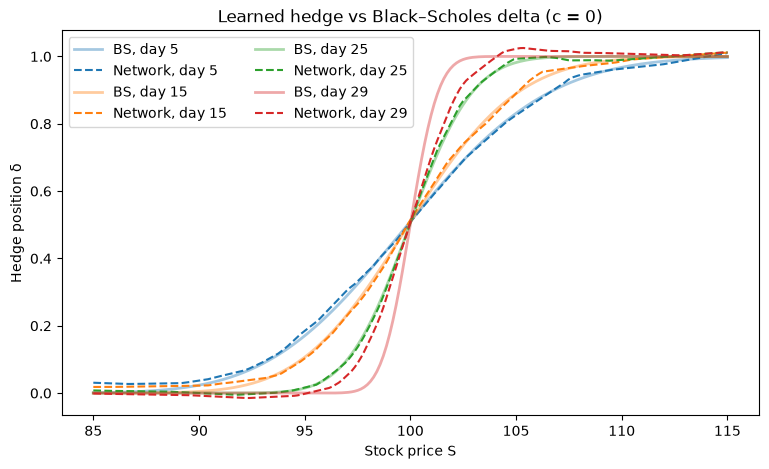

In [68]:
import matplotlib.pyplot as plt

S_grid = np.linspace(85, 115, 200)
fig, ax = plt.subplots(figsize=(9, 5))

for k, color in zip([5, 15, 25, 29], ["C0", "C1", "C2", "C3"]):
    tau_k = T - k * dt
    x1g = torch.tensor(np.log(S_grid / K) / (sigma * np.sqrt(T)), dtype=torch.float32)
    x2g = torch.full_like(x1g, tau_k / T)
    with torch.no_grad():
        d_net = net(torch.stack([x1g, x2g], dim=-1)).squeeze(-1).numpy()
    ax.plot(S_grid, bs_delta(S_grid, K, tau_k, sigma), color=color, lw=2, alpha=0.4, label=f"BS, day {k}")
    ax.plot(S_grid, d_net, color=color, ls="--", label=f"Network, day {k}")

ax.set_xlabel("Stock price S")
ax.set_ylabel("Hedge position δ")
ax.set_title("Learned hedge vs Black–Scholes delta (c = 0)")
ax.legend(ncol=2)
plt.savefig("../figures/net_vs_bs_delta.png", dpi=150, bbox_inches="tight")
plt.show()